1.Dataset description

In [3]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("ai_student_impact_dataset.csv")

df = pd.read_csv(DATA_PATH)


df = df.drop(columns=["Student_ID"])
print("\nColumn Student_ID is deleted !")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nFirst five rows:")
display(df.head())

print("\n")
continuous_features = ["Pre_Semester_GPA","Weekly_GenAI_Hours","Traditional_Study_Hours","Post_Semester_GPA","Skill_Retention_Score"]
categorical_features = [col for col in df.columns if col not in continuous_features]

print("Continuous features:\n", continuous_features)
print("\n")
print("Categorical features:\n", categorical_features)
print("\n")
print("Dataset information:")
df.info()


Column Student_ID is deleted !
Dataset shape: (50000, 15)

Column names:
['Major_Category', 'Year_of_Study', 'Pre_Semester_GPA', 'Weekly_GenAI_Hours', 'Primary_Use_Case', 'Prompt_Engineering_Skill', 'Tool_Diversity', 'Paid_Subscription', 'Traditional_Study_Hours', 'Perceived_AI_Dependency', 'Institutional_Policy', 'Anxiety_Level_During_Exams', 'Post_Semester_GPA', 'Skill_Retention_Score', 'Burnout_Risk_Level']

First five rows:


,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium




Continuous features:
 ['Pre_Semester_GPA', 'Weekly_GenAI_Hours', 'Traditional_Study_Hours', 'Post_Semester_GPA', 'Skill_Retention_Score']


Categorical features:
 ['Major_Category', 'Year_of_Study', 'Primary_Use_Case', 'Prompt_Engineering_Skill', 'Tool_Diversity', 'Paid_Subscription', 'Perceived_AI_Dependency', 'Institutional_Policy', 'Anxiety_Level_During_Exams', 'Burnout_Risk_Level']


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Major_Category              50000 non-null  str    
 1   Year_of_Study               50000 non-null  str    
 2   Pre_Semester_GPA            50000 non-null  float64
 3   Weekly_GenAI_Hours          50000 non-null  float64
 4   Primary_Use_Case            50000 non-null  str    
 5   Prompt_Engineering_Skill    50000 non-null  str    
 6   Tool_Diversity             

2. Data cleaning

In [4]:
print("\nMissing values per column:")
display(df.isna().sum().to_frame("Missing values"))


Missing values per column:


,Missing values
Major_Category,0
Year_of_Study,0
Pre_Semester_GPA,0
Weekly_GenAI_Hours,0
Primary_Use_Case,0
Prompt_Engineering_Skill,0
Tool_Diversity,0
Paid_Subscription,0
Traditional_Study_Hours,0
Perceived_AI_Dependency,0


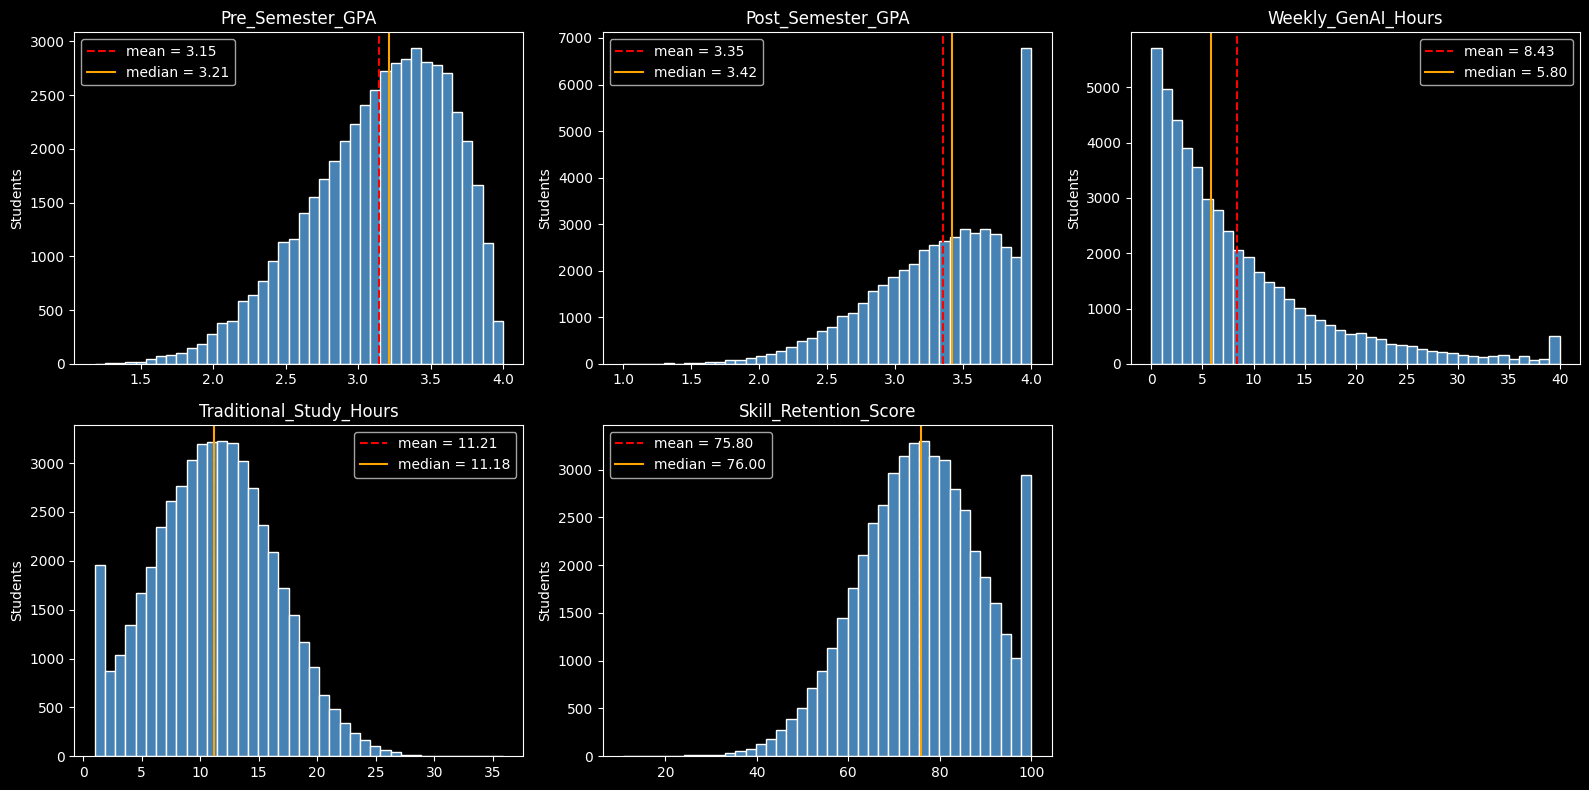

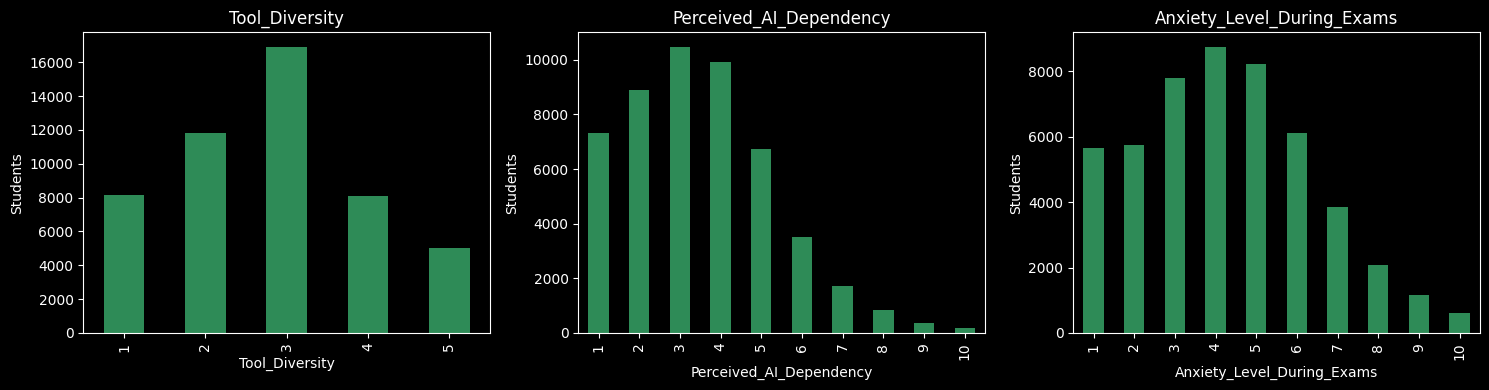


Major_Category
                Count  Percent
Major_Category                
STEM            15059     30.1
Business        12538     25.1
Humanities       9994     20.0
Medical          6476     13.0
Arts             5933     11.9

Year_of_Study
               Count  Percent
Year_of_Study                
Junior         11045     22.1
Freshman       11031     22.1
Senior         10634     21.3
Sophomore       9860     19.7
Graduate        7430     14.9

Primary_Use_Case
                           Count  Percent
Primary_Use_Case                         
Debugging/Troubleshooting  12295     24.6
Copywriting/Drafting       12011     24.0
Ideation                   10721     21.4
Summarizing_Reading         8633     17.3
Direct_Answer_Generation    6340     12.7

Prompt_Engineering_Skill
                          Count  Percent
Prompt_Engineering_Skill                
Beginner                  18495     37.0
Intermediate              17696     35.4
Advanced                  13809     27.6

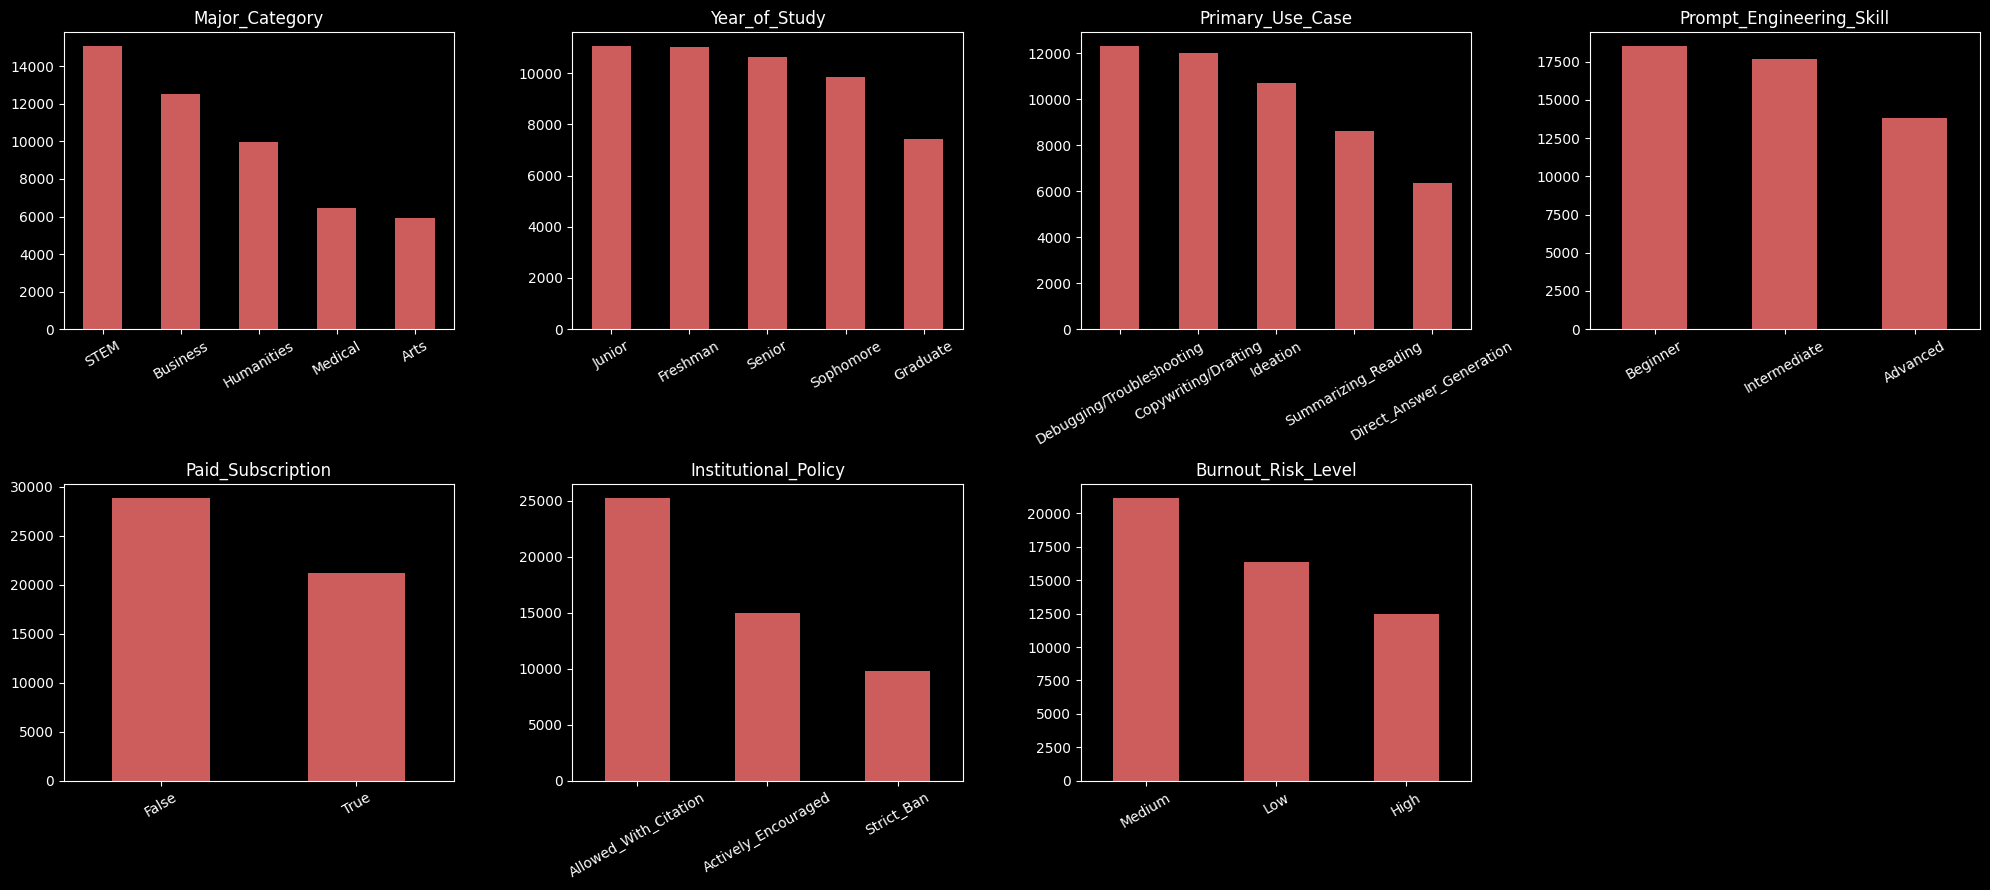

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("ai_student_impact_dataset.csv")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH).drop(columns=["Student_ID"])

continuous_features = ["Pre_Semester_GPA", "Post_Semester_GPA", "Weekly_GenAI_Hours",
                       "Traditional_Study_Hours", "Skill_Retention_Score"]
ordinal_features = ["Tool_Diversity", "Perceived_AI_Dependency", "Anxiety_Level_During_Exams"]
categorical_features = ["Major_Category", "Year_of_Study", "Primary_Use_Case",
                        "Prompt_Engineering_Skill", "Paid_Subscription",
                        "Institutional_Policy", "Burnout_Risk_Level"]

# %%
stats = df[continuous_features + ordinal_features].agg(["min", "mean", "max", "median", "std"]).T.round(3)
stats.columns = ["Min", "Mean", "Max", "Median", "Std"]
stats

# %%
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), continuous_features):
    ax.hist(df[col], bins=40, color="steelblue", edgecolor="white")
    ax.axvline(df[col].mean(), color="red", linestyle="--", label=f"mean = {df[col].mean():.2f}")
    ax.axvline(df[col].median(), color="orange", linestyle="-", label=f"median = {df[col].median():.2f}")
    ax.set_title(col)
    ax.set_ylabel("Students")
    ax.legend()
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "hist_continuous.png", dpi=200)
plt.show()

# %%
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ordinal_features):
    df[col].value_counts().sort_index().plot.bar(ax=ax, color="seagreen")
    ax.set_title(col)
    ax.set_ylabel("Students")
plt.tight_layout()
plt.savefig(FIG_DIR / "bar_ordinal.png", dpi=200)
plt.show()

# %%
for col in categorical_features:
    counts = df[col].value_counts()
    table = pd.DataFrame({"Count": counts, "Percent": (counts / len(df) * 100).round(1)})
    print(f"\n{col}")
    print(table)

# %%
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.ravel(), categorical_features):
    df[col].value_counts().plot.bar(ax=ax, color="indianred")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "bar_categorical.png", dpi=200)
plt.show()


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_PATH = Path("ai_student_impact_dataset.csv")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH).drop(columns=["Student_ID"])

numeric_features = ["Pre_Semester_GPA", "Post_Semester_GPA", "Weekly_GenAI_Hours",
                    "Traditional_Study_Hours", "Skill_Retention_Score",
                    "Tool_Diversity", "Perceived_AI_Dependency", "Anxiety_Level_During_Exams"]
burnout_order = ["Low", "Medium", "High"]

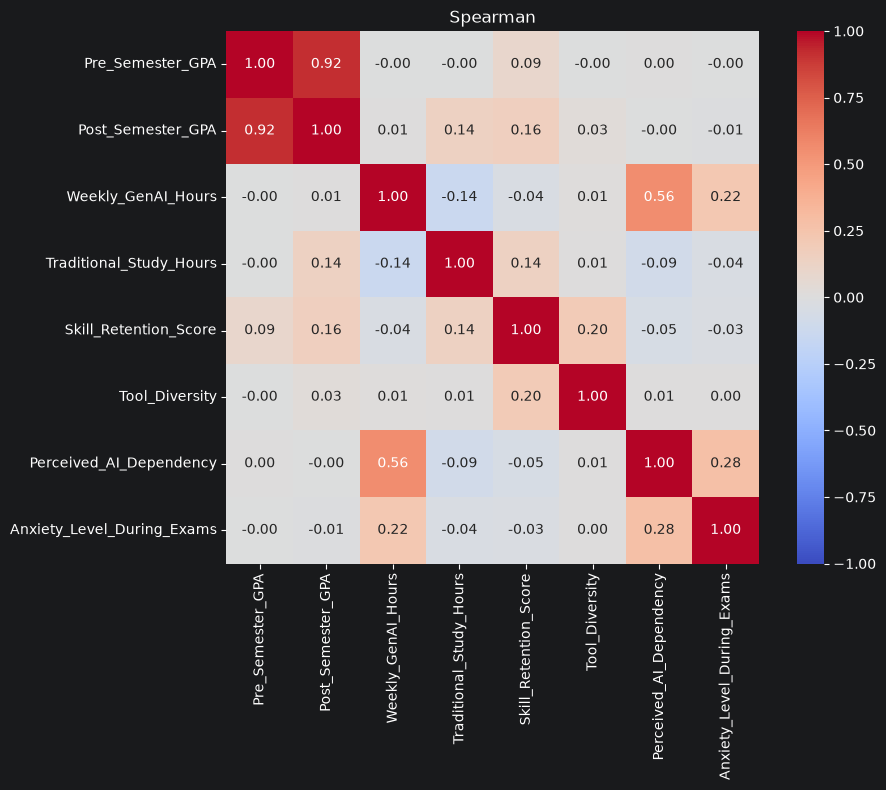

In [2]:
plt.figure(figsize=(10, 8))

corr = df[numeric_features].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)

plt.title("Spearman")
plt.tight_layout()
plt.savefig(FIG_DIR / "heatmap_correlations.png", dpi=200)
plt.show()

In [3]:
#A REGLER !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
pairs = df[numeric_features].corr(method="spearman").abs().unstack()
pairs = pairs[pairs.index.get_level_values(0) < pairs.index.get_level_values(1)]
top_pairs = pairs.sort_values(ascending=False).head(6)
top_pairs

Post_Semester_GPA           Pre_Semester_GPA           0.917233
Perceived_AI_Dependency     Weekly_GenAI_Hours         0.555155
Anxiety_Level_During_Exams  Perceived_AI_Dependency    0.280295
                            Weekly_GenAI_Hours         0.221188
Skill_Retention_Score       Tool_Diversity             0.201704
Post_Semester_GPA           Skill_Retention_Score      0.159872
dtype: float64

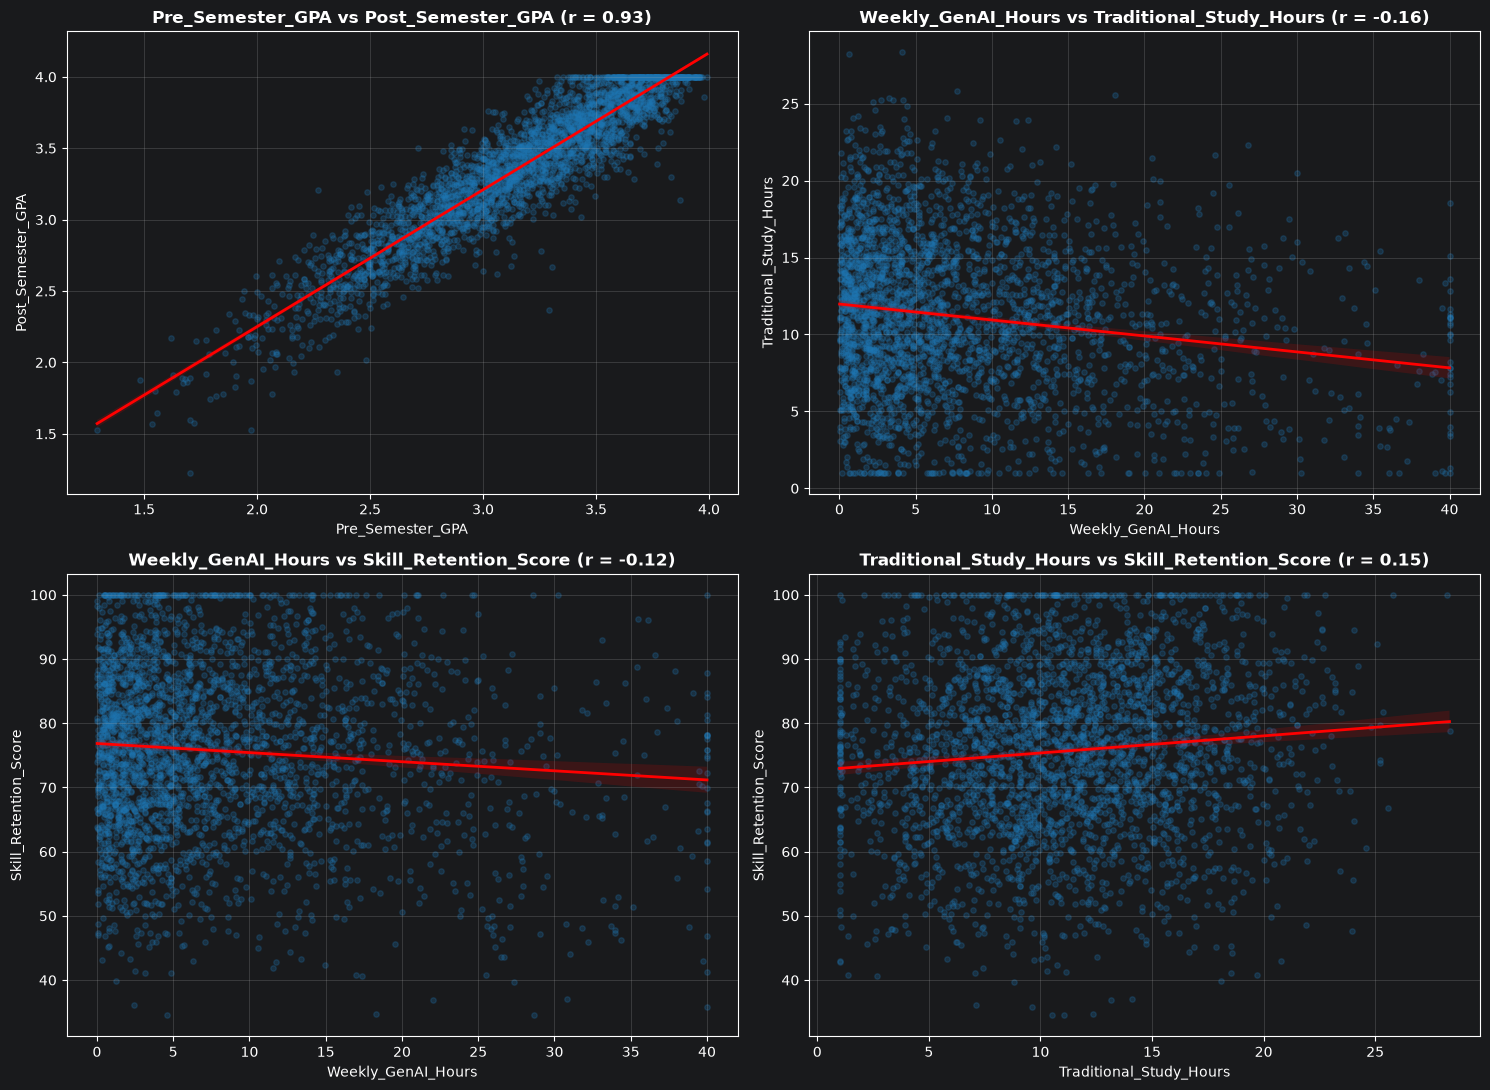

In [4]:
sample_df = df.sample(n=3000, random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

pairs = [
    ("Pre_Semester_GPA", "Post_Semester_GPA", "Pre_Semester_GPA vs Post_Semester_GPA (r = 0.93)"),
    ("Weekly_GenAI_Hours", "Traditional_Study_Hours", "Weekly_GenAI_Hours vs Traditional_Study_Hours (r = -0.16)"),
    ("Weekly_GenAI_Hours", "Skill_Retention_Score", "Weekly_GenAI_Hours vs Skill_Retention_Score (r = -0.12)"),
    ("Traditional_Study_Hours", "Skill_Retention_Score", "Traditional_Study_Hours vs Skill_Retention_Score (r = 0.15)")
]

for ax, (x_col, y_col, title) in zip(axes.flat, pairs):
    sns.regplot(
        data=sample_df, x=x_col, y=y_col, ax=ax,
        scatter_kws={"alpha": 0.25, "s": 15, "color": "#1f77b4"},
        line_kws={"color": "red", "linewidth": 2}
    )
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("scatter_plots.png", dpi=300)
plt.show()

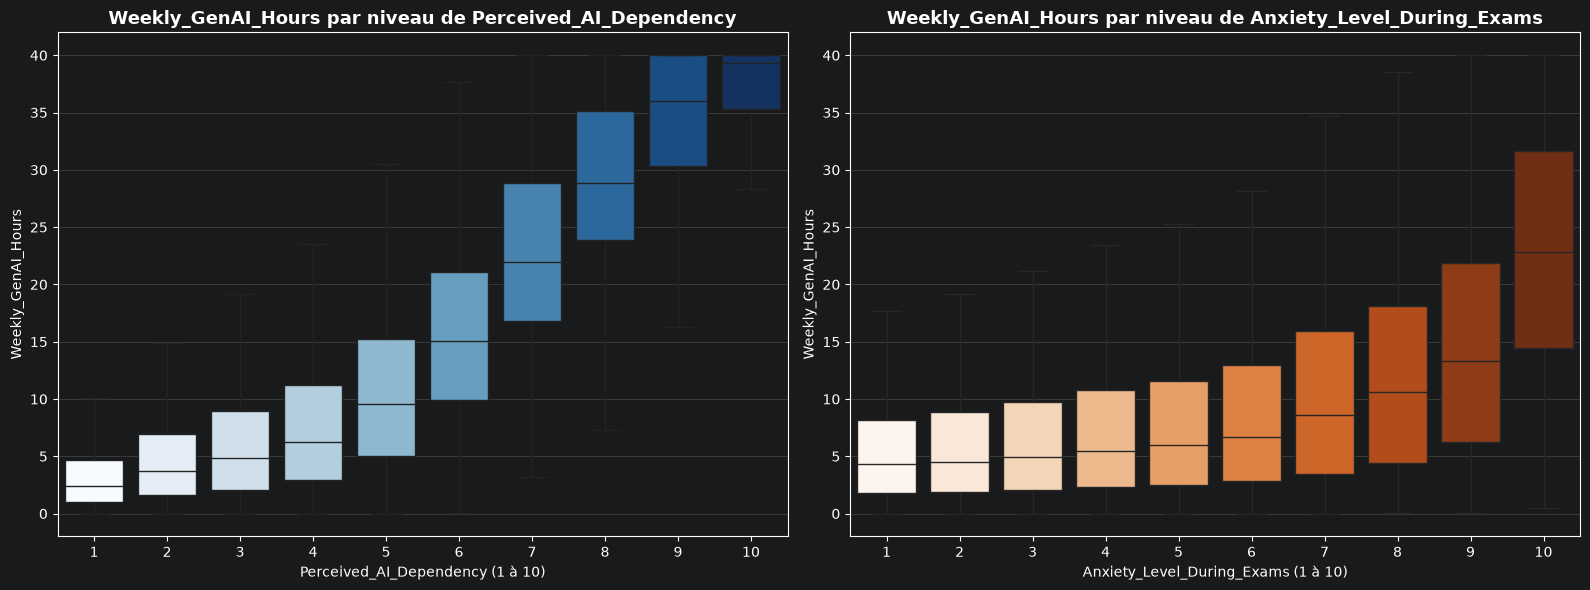

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot 1 : Dépendance perçue à l'IA vs Heures hebdomadaires d'IA
sns.boxplot(
    data=df, x="Perceived_AI_Dependency", y="Weekly_GenAI_Hours",
    hue="Perceived_AI_Dependency", palette="Blues", legend=False,
    ax=axes[0], showfliers=False
)
axes[0].set_title("Weekly_GenAI_Hours par niveau de Perceived_AI_Dependency", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Perceived_AI_Dependency (1 à 10)")
axes[0].set_ylabel("Weekly_GenAI_Hours")
axes[0].grid(True, axis="y", alpha=0.3)

# Boxplot 2 : Niveau d'anxiété aux examens vs Heures hebdomadaires d'IA
sns.boxplot(
    data=df, x="Anxiety_Level_During_Exams", y="Weekly_GenAI_Hours",
    hue="Anxiety_Level_During_Exams", palette="Oranges", legend=False,
    ax=axes[1], showfliers=False
)
axes[1].set_title("Weekly_GenAI_Hours par niveau de Anxiety_Level_During_Exams", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Anxiety_Level_During_Exams (1 à 10)")
axes[1].set_ylabel("Weekly_GenAI_Hours")
axes[1].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("boxplots.png", dpi=300)
plt.show()

In [7]:
df.assign(Burnout_Code=df["Burnout_Risk_Level"].map({"Low": 0, "Medium": 1, "High": 2}))[
    numeric_features + ["Burnout_Code"]].corr(method="spearman")["Burnout_Code"].drop("Burnout_Code").round(3).sort_values()


Traditional_Study_Hours      -0.133
Pre_Semester_GPA             -0.094
Post_Semester_GPA            -0.091
Skill_Retention_Score        -0.049
Tool_Diversity                0.005
Anxiety_Level_During_Exams    0.149
Perceived_AI_Dependency       0.342
Weekly_GenAI_Hours            0.435
Name: Burnout_Code, dtype: float64

3. Clustering

Computing k = 2...
Computing k = 3...
Computing k = 4...
Computing k = 5...
Computing k = 6...
Computing k = 7...
Computing k = 8...
Computing k = 9...
Computing k = 10...
Computing k = 11...
Computing k = 12...
Computing k = 13...
Computing k = 14...
Computing k = 15...
Computing k = 16...
Computing k = 17...
Computing k = 18...
Computing k = 19...
Graph saved as 'kmeans_evaluation.png' !


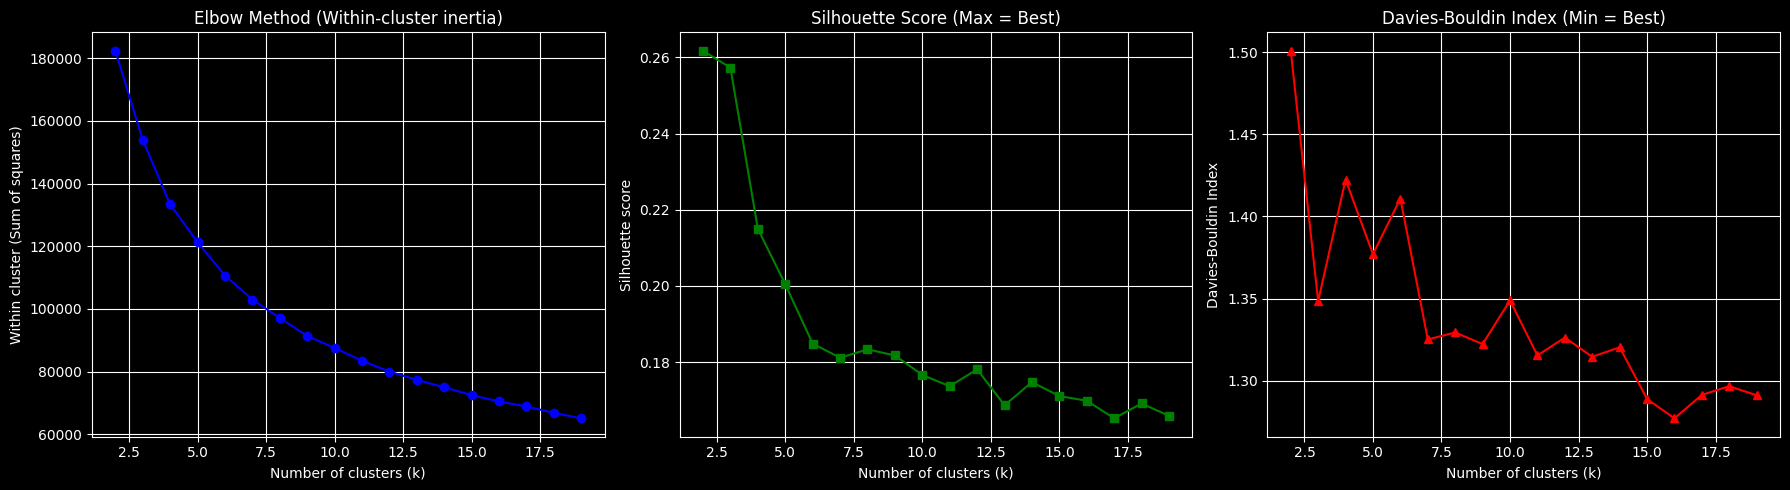

,k,Within-cluster inertia,Silhouette_Score,Davies_Bouldin_Index
0,2,182390.727126,0.261757,1.500969
1,3,153953.231698,0.257281,1.348398
2,4,133330.521891,0.214984,1.422479
3,5,121275.255768,0.200444,1.376981
4,6,110614.547732,0.184880,1.410921
5,7,102984.062332,0.181180,1.325067
6,8,97102.756867,0.183369,1.329311
7,9,91344.048742,0.181772,1.322249
8,10,87564.433047,0.176655,1.348895
9,11,83424.770167,0.173686,1.315321



Students repartition per cluster :


,Number of students
Cluster,
2,26516
0,16416
1,7068



Cluster global profile :


,Pre_Semester_GPA,Post_Semester_GPA,Weekly_GenAI_Hours,Traditional_Study_Hours,Skill_Retention_Score
Cluster,,,,,
0,2.62,2.81,6.26,10.91,73.57
1,3.24,3.39,23.59,8.19,68.74
2,3.45,3.67,5.73,12.20,79.06


In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[continuous_features])


K_range = range(2, 20)
inertias = []
silhouette_scores = []
db_scores = []

for k in K_range:
    print(f"Computing k = {k}...")
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init='auto')
    labels = kmeans.fit_predict(X_scaled)

    inertias.append(kmeans.inertia_)

    silhouette_scores.append(silhouette_score(X_scaled, labels, sample_size=2000, random_state=None))
    db_scores.append(davies_bouldin_score(X_scaled, labels))


fig, axes = plt.subplots(1, 3, figsize=(18, 5))


axes[0].plot(K_range, inertias, marker='o', color='b')
axes[0].set_title("Elbow Method (Within-cluster inertia)")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Within cluster (Sum of squares)")
axes[0].grid(True)


axes[1].plot(K_range, silhouette_scores, marker='s', color='g')
axes[1].set_title("Silhouette Score (Max = Best)")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].grid(True)


axes[2].plot(K_range, db_scores, marker='^', color='r')
axes[2].set_title("Davies-Bouldin Index (Min = Best)")
axes[2].set_xlabel("Number of clusters (k)")
axes[2].set_ylabel("Davies-Bouldin Index")
axes[2].grid(True)

plt.tight_layout()
plt.savefig("kmeans_evaluation.png", dpi=300)
print("Graph saved as 'kmeans_evaluation.png' !")
plt.show()


metrics_df = pd.DataFrame({
    "k": list(K_range),
    "Within-cluster inertia": inertias,
    "Silhouette_Score": silhouette_scores,
    "Davies_Bouldin_Index": db_scores
})
display(metrics_df)


optimal_k = 3

kmeans_final = KMeans(n_clusters=optimal_k, random_state=None, n_init='auto')
df["Cluster"] = kmeans_final.fit_predict(X_scaled)

print("\nStudents repartition per cluster :")
display(df["Cluster"].value_counts().to_frame("Number of students"))

print("\nCluster global profile :")
cluster_profile = df.groupby("Cluster")[continuous_features].mean().round(2)
display(cluster_profile)

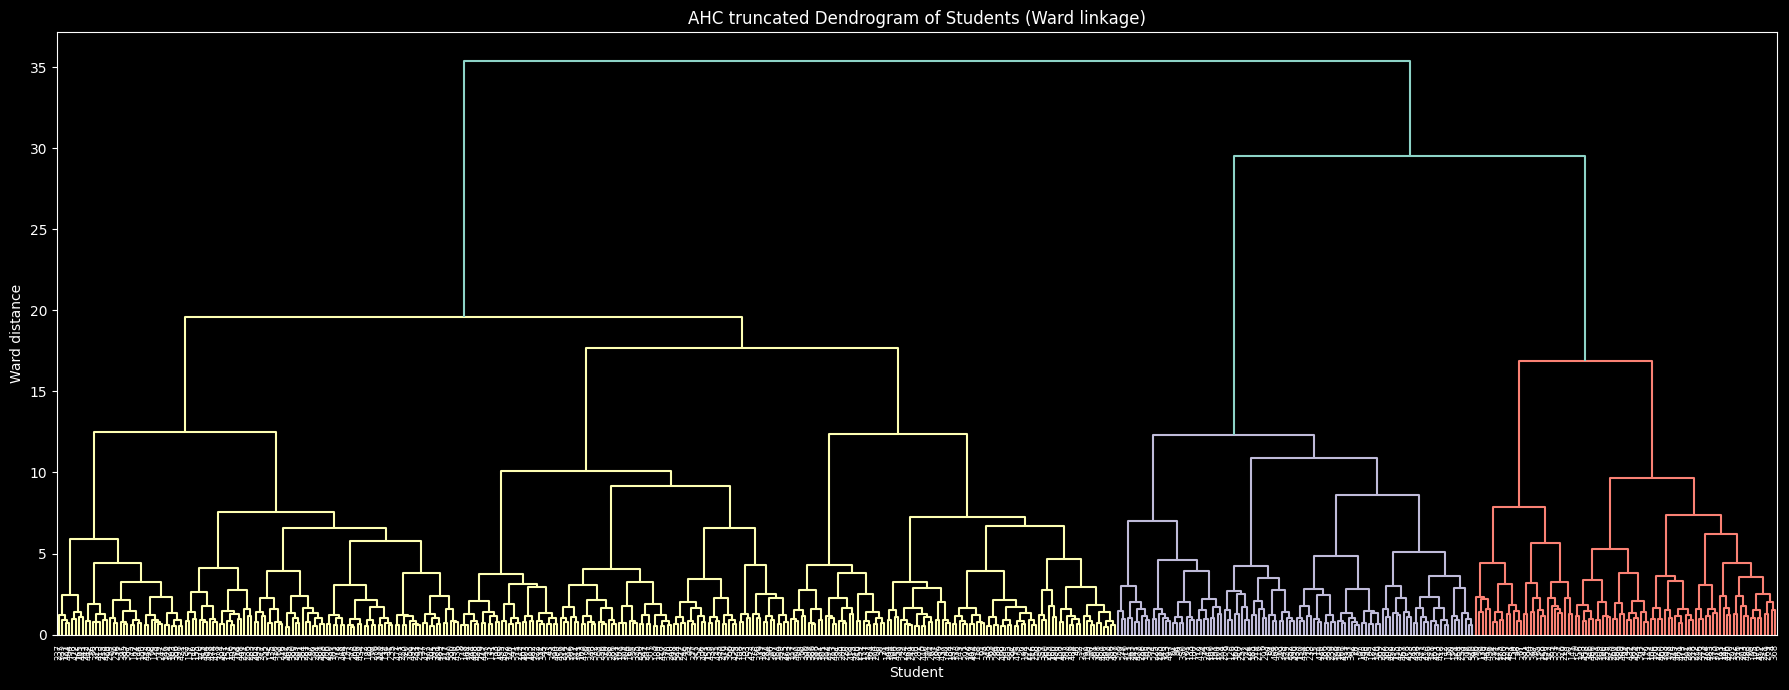

Number of clusters: 3


,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level,Cluster
12500,Arts,Junior,3.254,3.64,Summarizing_Reading,Beginner,1,True,8.55,4,Allowed_With_Citation,4,3.496,63.58,Low,1
1,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low,1
38827,Business,Freshman,3.566,8.76,Summarizing_Reading,Beginner,2,False,24.89,1,Allowed_With_Citation,2,3.809,71.39,Medium,1
3,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium,1
4,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium,1
5,STEM,Junior,3.449,6.50,Debugging/Troubleshooting,Beginner,1,False,14.19,4,Allowed_With_Citation,5,3.666,65.92,High,1
38828,STEM,Freshman,3.272,8.97,Debugging/Troubleshooting,Beginner,1,False,6.86,2,Actively_Encouraged,1,3.485,77.42,Medium,1
38831,Humanities,Freshman,3.137,11.52,Copywriting/Drafting,Advanced,5,True,7.52,3,Actively_Encouraged,5,3.123,77.78,Medium,1
8,Business,Sophomore,3.420,2.00,Debugging/Troubleshooting,Beginner,2,True,2.87,1,Strict_Ban,5,3.396,55.71,Medium,1
38832,Humanities,Freshman,3.580,1.87,Direct_Answer_Generation,Advanced,4,False,13.08,1,Strict_Ban,1,3.599,53.65,Medium,1


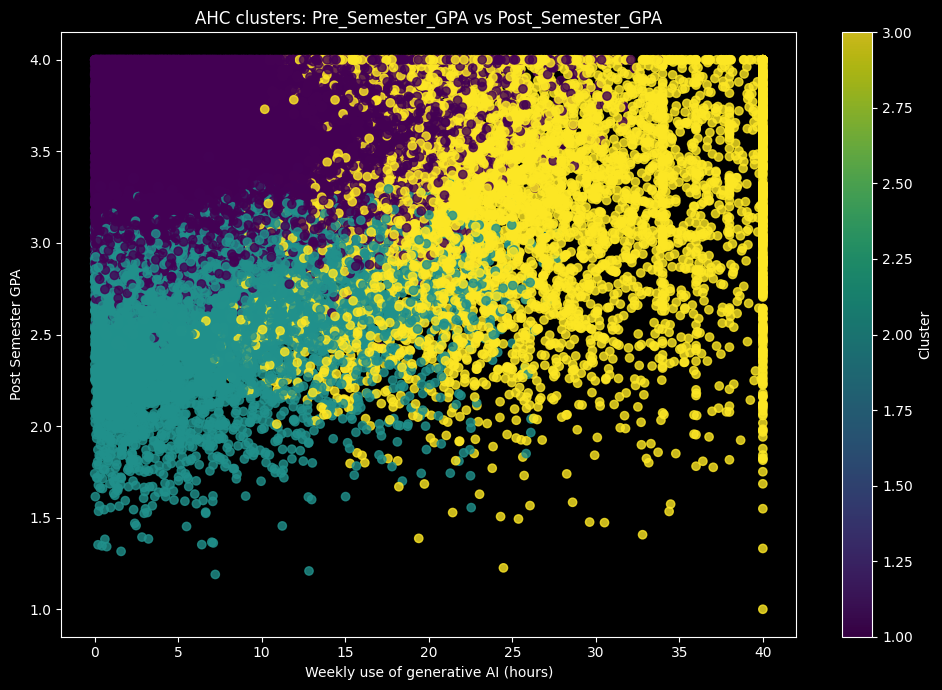

In [7]:
from sklearn.cluster import MiniBatchKMeans
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

n_micro_clusters = 500
mbk = MiniBatchKMeans(
    n_clusters=n_micro_clusters, batch_size=1024, random_state=42
)
mbk.fit(X_scaled)

centroids = mbk.cluster_centers_

Z_fast = linkage(centroids, method='ward')


plt.figure(figsize=(18, 7))
dendrogram(
    Z_fast,
    leaf_rotation=90,
    leaf_font_size=6,
)

plt.title("AHC truncated Dendrogram of Students (Ward linkage)")
plt.xlabel("Student")
plt.ylabel("Ward distance")
plt.tight_layout()
plt.show()

distance_threshold = 25.0


clusters_by_distance = fcluster(Z_fast, t=distance_threshold, criterion="distance")

final_sample_clusters = clusters_by_distance[mbk.labels_]


data_by_distance = df.copy()
data_by_distance["Cluster"] = final_sample_clusters
print("Number of clusters:", data_by_distance["Cluster"].nunique())
display(data_by_distance.sort_values("Cluster").head(20))


plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    #data_by_distance["Pre_Semester_GPA"],
    data_by_distance["Weekly_GenAI_Hours"],
    #data_by_distance["Traditional_Study_Hours"],
    data_by_distance["Post_Semester_GPA"],
    #data_by_distance["Skill_Retention_Score"],
    c=data_by_distance["Cluster"],
    cmap="viridis",
    alpha=0.8
)
plt.title("AHC clusters: Pre_Semester_GPA vs Post_Semester_GPA")
plt.xlabel("Weekly use of generative AI (hours)")
plt.ylabel("Post Semester GPA")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

#ADD EVALUATION

4. Simple and multiple linear regression

In [8]:
#TO ADD -> SEE NATHAN
# %%
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

DATA_PATH = Path("ai_student_impact_dataset.csv")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH).drop(columns=["Student_ID"])

target = "Post_Semester_GPA"
simple_features = ["Pre_Semester_GPA"]
multiple_features = [
    "Pre_Semester_GPA",
    "Weekly_GenAI_Hours",
    "Traditional_Study_Hours",
    "Skill_Retention_Score",
]
y = df[target]

Intercept : 0.3311
Slope (Pre_Semester_GPA) : 0.9593
MSE : 0.0347  |  R2 : 0.8589


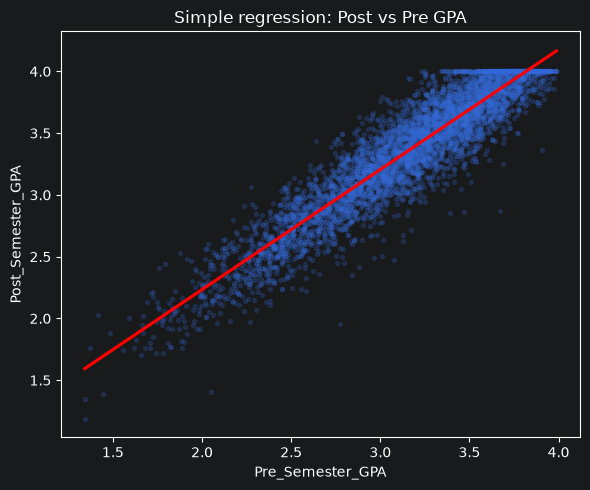

In [9]:
X_simple = df[simple_features]
model_simple = LinearRegression().fit(X_simple, y)
pred_simple = model_simple.predict(X_simple)
mse_simple = mean_squared_error(y, pred_simple)
r2_simple = r2_score(y, pred_simple)

print(f"Intercept : {model_simple.intercept_:.4f}")
print(f"Slope (Pre_Semester_GPA) : {model_simple.coef_[0]:.4f}")
print(f"MSE : {mse_simple:.4f}  |  R2 : {r2_simple:.4f}")

fig, ax = plt.subplots(figsize=(6, 5))
sns.regplot(
    data=df.sample(5000, random_state=0),
    x="Pre_Semester_GPA",
    y=target,
    scatter_kws={"alpha": 0.2, "s": 8},
    line_kws={"color": "red"},
    ax=ax,
)
ax.set_title("Simple regression: Post vs Pre GPA")
plt.tight_layout()
plt.savefig(FIG_DIR / "regression_simple.png", dpi=150)
plt.show()

In [10]:
X_multiple = df[multiple_features]
model_multiple = LinearRegression().fit(X_multiple, y)
pred_multiple = model_multiple.predict(X_multiple)
mse_multiple = mean_squared_error(y, pred_multiple)
r2_multiple = r2_score(y, pred_multiple)
n, p = X_multiple.shape
r2_adjusted = 1 - (1 - r2_multiple) * (n - 1) / (n - p - 1)

coefficients = pd.DataFrame(
    {
        "coefficient": model_multiple.coef_,
        "standardized": model_multiple.coef_ * X_multiple.std().values / y.std(),
    },
    index=multiple_features,
).round(4)

print(f"Intercept : {model_multiple.intercept_:.4f}")
print(coefficients)
print(f"MSE : {mse_multiple:.4f}  |  R2 : {r2_multiple:.4f}  |  adjusted R2 : {r2_adjusted:.4f}")

Intercept : 0.0287
                         coefficient  standardized
Pre_Semester_GPA              0.9539        0.9215
Weekly_GenAI_Hours            0.0006        0.0107
Traditional_Study_Hours       0.0130        0.1348
Skill_Retention_Score         0.0022        0.0597
MSE : 0.0289  |  R2 : 0.8825  |  adjusted R2 : 0.8825


             MSE    RMSE      R2
Simple    0.0347  0.1862  0.8589
Multiple  0.0289  0.1699  0.8825


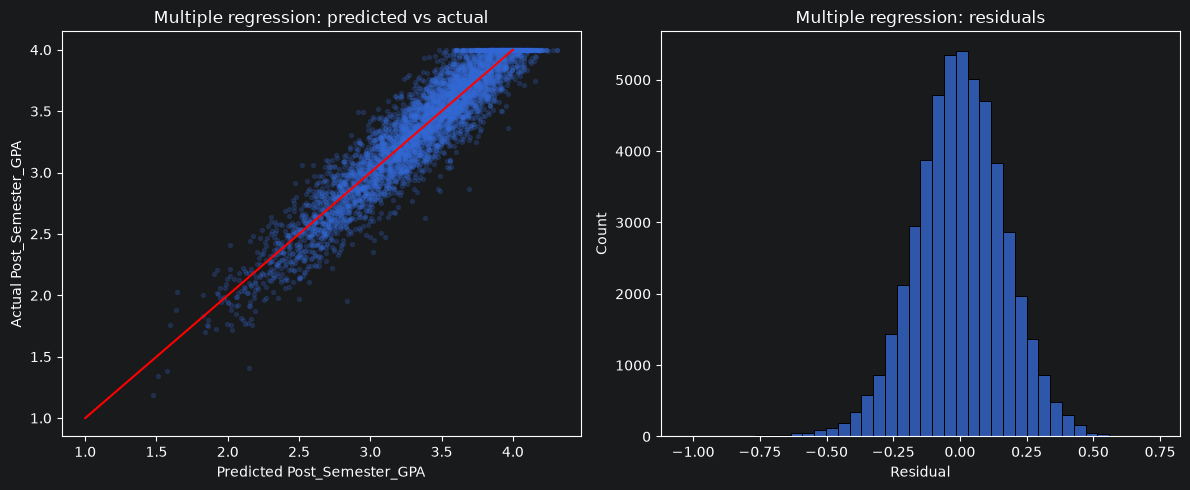

In [12]:
comparison = pd.DataFrame(
    {
        "MSE": [mse_simple, mse_multiple],
        "RMSE": [mse_simple ** 0.5, mse_multiple ** 0.5],
        "R2": [r2_simple, r2_multiple],
    },
    index=["Simple", "Multiple"],
).round(4)
print(comparison)

residuals = y - pred_multiple
sample = df.sample(5000, random_state=0).index

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(pred_multiple[sample], y.loc[sample], alpha=0.2, s=8)
axes[0].plot([1, 4], [1, 4], color="red")
axes[0].set_xlabel("Predicted Post_Semester_GPA")
axes[0].set_ylabel("Actual Post_Semester_GPA")
axes[0].set_title("Multiple regression: predicted vs actual")
sns.histplot(residuals, bins=40, ax=axes[1])
axes[1].set_xlabel("Residual")
axes[1].set_title("Multiple regression: residuals")
plt.tight_layout()
plt.savefig(FIG_DIR / "regression_multiple.png", dpi=150)
plt.show()

5. Classification with KNN

In [9]:
from sklearn.model_selection import train_test_split

DATA_PATH = Path("ai_student_impact_dataset.csv")
df = pd.read_csv(DATA_PATH)


df = df.drop(columns=["Student_ID"])
print("\nColumn Student_ID is deleted !")


target_col = "Burnout_Risk_Level"
y = df[target_col]

cols_to_drop = [target_col]
X = df.drop(columns=cols_to_drop)


X_encoded = pd.get_dummies(X,drop_first=True)


X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42, stratify=y)


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set size: {X_train_scaled.shape}")
print(f"Test set size: {X_test_scaled.shape}")
print("\n")

print("Training labels:\n", y_train[:105])
print("Test labels:\n", y_train[:45])


Column Student_ID is deleted !
Training set size: (40000, 25)
Test set size: (10000, 25)


Training labels:
 1497       High
4233     Medium
39113      High
8818        Low
2082     Medium
          ...  
41976      High
16702      High
9067     Medium
23485      High
42379       Low
Name: Burnout_Risk_Level, Length: 105, dtype: str
Test labels:
 1497       High
4233     Medium
39113      High
8818        Low
2082     Medium
29715    Medium
29512    Medium
45159       Low
1905     Medium
4353     Medium
42501      High
19020       Low
26579    Medium
18659       Low
42824    Medium
16978       Low
24940    Medium
17203      High
15308      High
14590       Low
12576    Medium
2240       High
40467       Low
46074    Medium
24832       Low
21020    Medium
43587      High
12608       Low
9445       High
39306       Low
35196      High
35589    Medium
9066       High
16976    Medium
6197       High
28147      High
28567    Medium
16140    Medium
39461    Medium
36654    Medium
15823     


Best k: 75 with accuracy: 50.48%


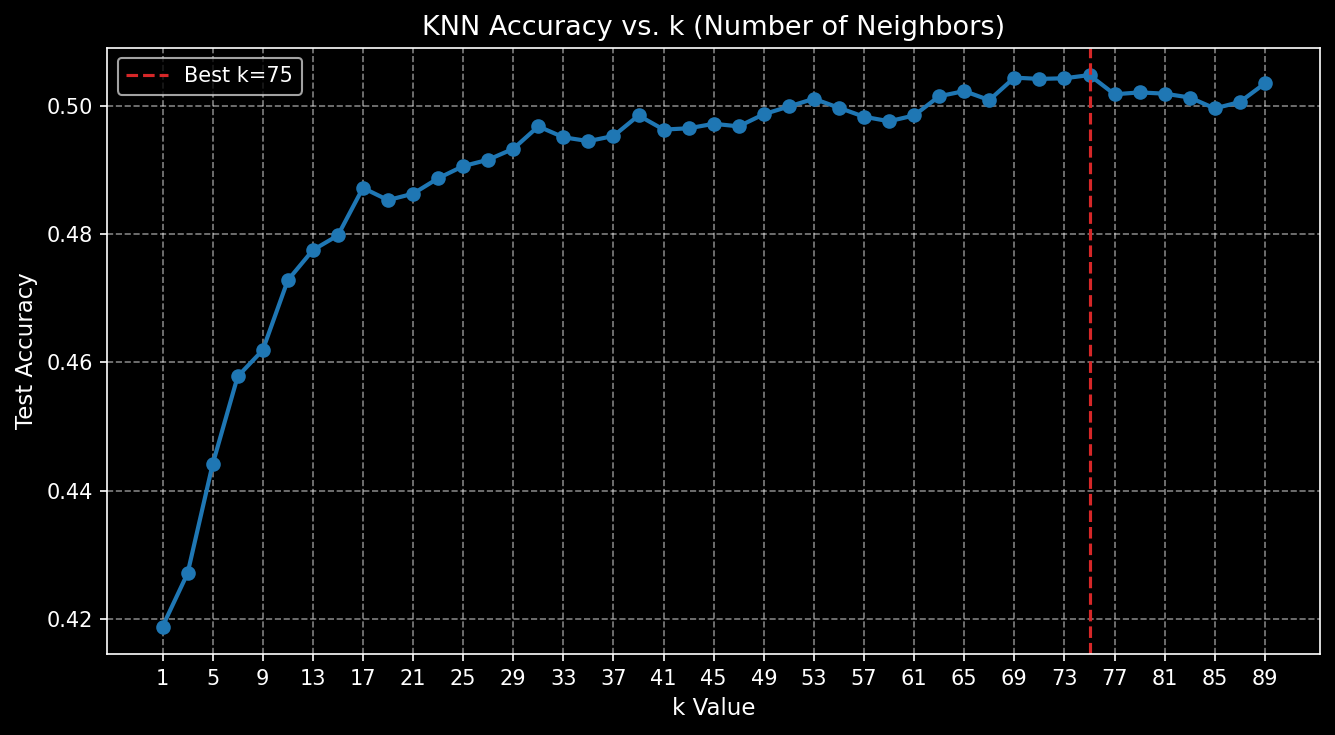

Final Model Test Accuracy: 50.48%
Predicted labels:
 ['Medium' 'Medium' 'Low' ... 'Medium' 'Low' 'Medium']
Real labels:
 18437    Medium
5385     Medium
41097       Low
46083    Medium
46666      High
          ...  
32284    Medium
30953      High
9899     Medium
7551        Low
43395    Medium
Name: Burnout_Risk_Level, Length: 10000, dtype: str

Accuracy : 0.5035

Classification report :
               precision    recall  f1-score   support

        High       0.75      0.30      0.43      2497
         Low       0.50      0.42      0.46      3274
      Medium       0.47      0.68      0.56      4229

    accuracy                           0.50     10000
   macro avg       0.57      0.47      0.48     10000
weighted avg       0.55      0.50      0.49     10000



In [13]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

k_values = list(range(1, 91, 2))
accuracy_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    accuracy_scores.append(accuracy_score(y_test, y_pred))


best_k = k_values[np.argmax(accuracy_scores)]
best_acc = max(accuracy_scores)
print(f"\nBest k: {best_k} with accuracy: {best_acc * 100:.2f}%")


plt.figure(figsize=(9, 5), dpi=150)
plt.plot(k_values, accuracy_scores, marker='o', color='tab:blue', linewidth=2)
plt.axvline(best_k, color='tab:red', linestyle='--', label=f'Best k={best_k}')
plt.title("KNN Accuracy vs. k (Number of Neighbors)", fontsize=13)
plt.xlabel("k Value", fontsize=11)
plt.ylabel("Test Accuracy", fontsize=11)
plt.xticks(k_values[::2])  # Show every second tick for readability
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


final_knn = KNeighborsClassifier(n_neighbors=best_k)
final_knn.fit(X_train_scaled, y_train)
final_pred = final_knn.predict(X_test_scaled)

print(f"Final Model Test Accuracy: {accuracy_score(y_test, final_pred) * 100:.2f}%")


y_pred = knn.predict(X_test_scaled)
print("Predicted labels:\n", y_pred)
print("Real labels:\n", y_test)


print("\nClassification report :\n", classification_report(y_test, y_pred))

7.Decisional tree

In [13]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

DATA_PATH = Path("ai_student_impact_dataset.csv")

df = pd.read_csv(DATA_PATH)


target = "Burnout_Risk_Level"
X = df.drop(columns=["Student_ID", target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Taille de X_train :", X_train.shape) # (40000, 14) au lieu de 15
print("Taille de X_test  :", X_test.shape)  # (10000, 14) au lieu de 15

cat_cols = X.select_dtypes(include=["object", "str", "bool"]).columns.tolist()
num_cols = X.select_dtypes(exclude=["object", "str", "bool"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ]
)

clf_tree = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("tree", DecisionTreeClassifier(max_depth=4, random_state=42))
])

clf_tree.fit(X_train, y_train)

y_pred = clf_tree.predict(X_test)
print("\nAccuracy sur le jeu de test :", round(accuracy_score(y_test, y_pred), 4))
print("\nRapport de classification :\n", classification_report(y_test, y_pred))

Taille de X_train : (40000, 14)
Taille de X_test  : (10000, 14)

Accuracy sur le jeu de test : 0.5191

Rapport de classification :
               precision    recall  f1-score   support

        High       0.63      0.48      0.55      2497
         Low       0.51      0.51      0.51      3274
      Medium       0.48      0.55      0.51      4229

    accuracy                           0.52     10000
   macro avg       0.54      0.51      0.52     10000
weighted avg       0.53      0.52      0.52     10000

